# 문서 이미지 노이즈 제거: 층을 늘리는 것보다 정보가 흐르는 길이 중요했다

**목표:** 얼룩·구김·접힘으로 손상된 문서 이미지(`train`)를 깨끗한 원본(`train_cleaned`)으로 되돌리는 CNN 오토인코더를 만들고, RMSE·PSNR로 복원 품질을 평가하기

**진행 순서**
1. 환경 준비
2. 데이터 로드 및 전처리 — 이미지 크기 확인, 검증용 분리, 기준선
3. 크기 문제 해결 — 420×540과 258×540을 함께 다루는 방법
4. 모델 설계 — Conv2d 인코더 + ConvTranspose2d 디코더
5. 모델 학습 — 손실 함수와 옵티마이저
6. 성능 개선 실험 — 깊이·채널, 스킵 커넥션, 데이터 증강
7. 최종 모델
8. 복원 결과 시각화
9. 테스트 예측과 제출 파일
10. 정리

## 1. 환경 준비

In [1]:
import os, math, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 0
DATA_DIR = "denoising"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False      # 실행마다 같은 연산 방식을 쓰도록 고정
torch.backends.cudnn.deterministic = True
print("device:", device)

device: cuda


## 2. 데이터 로드 및 전처리

### 2-1. 이미지 불러오기

- 픽셀값(0~255)을 float32로 바꾼 뒤 255로 나눠 **0~1**로 맞춥니다. 모델의 마지막 Sigmoid 출력도 0~1이라 범위가 같아집니다.

In [2]:
def load_folder(name):
    files = sorted(os.listdir(os.path.join(DATA_DIR, name)), key=lambda f: int(f[:-4])) 
    images = [np.array(Image.open(os.path.join(DATA_DIR, name, f)), dtype=np.float32) / 255 for f in files]
    return files, images

train_files, noisy = load_folder("train")
clean_files, clean = load_folder("train_cleaned")
test_files, test_imgs = load_folder("test")

print("짝이 맞는가:", train_files == clean_files)
for name, imgs in [("train", noisy), ("train_cleaned", clean), ("test", test_imgs)]:
    print(f"{name:14s} {len(imgs)}장, (높이, 너비) 분포: {dict(Counter(im.shape for im in imgs))}")
print("픽셀 범위:", noisy[0].min(), "~", noisy[0].max())

짝이 맞는가: True
train          144장, (높이, 너비) 분포: {(258, 540): 48, (420, 540): 96}
train_cleaned  144장, (높이, 너비) 분포: {(258, 540): 48, (420, 540): 96}
test           72장, (높이, 너비) 분포: {(258, 540): 24, (420, 540): 48}
픽셀 범위: 0.0 ~ 0.9647059


**해석**
- train과 train_cleaned의 파일 이름이 1:1로 맞아 짝 데이터로 바로 쓸 수 있습니다.
- 높이가 **420과 258 두 종류**(너비는 540으로 같음)입니다. test도 같은 두 크기라서, 한 가지 크기로만 동작하는 모델은 쓸 수 없습니다. → 3장에서 해결합니다.
- 픽셀은 255로 나눠 0~1 범위로 맞췄습니다. 출력층에 Sigmoid를 써서 같은 범위로 내보내기 위함입니다.

### 2-2. 검증용 데이터 분리

test에는 원본이 없어서 점수를 직접 잴 수 없습니다. 그래서 train 144쌍 중 **24쌍을 검증용으로 떼어** 학습에 쓰지 않고, 모든 모델을 같은 24장으로 비교합니다.

In [3]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(noisy))
val_idx, tr_idx = perm[:24], perm[24:]
print("학습", len(tr_idx), "장 / 검증", len(val_idx), "장")
print("검증 크기 분포:", dict(Counter(noisy[i].shape for i in val_idx)))

학습 120 장 / 검증 24 장
검증 크기 분포: {(420, 540): 18, (258, 540): 6}


### 2-3. 손상본과 원본 비교

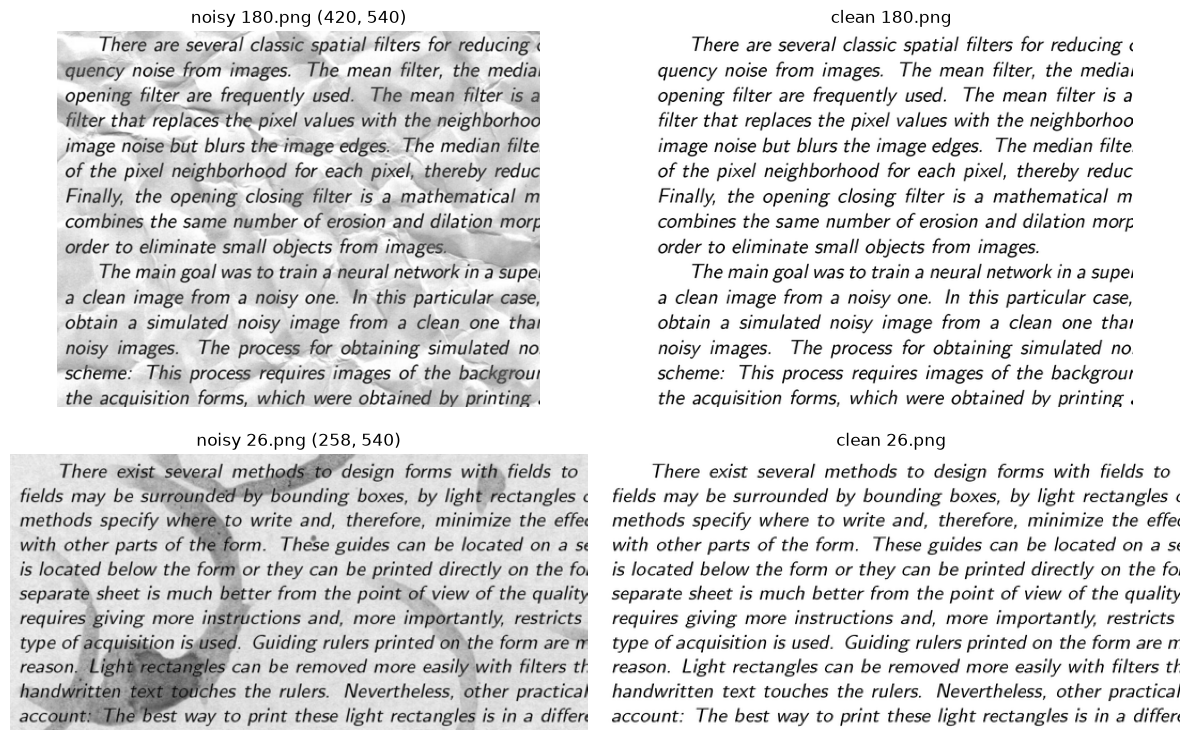

In [4]:
show_ids = [i for i in val_idx if noisy[i].shape[0] == 420][:1] + [i for i in val_idx if noisy[i].shape[0] == 258][:1]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, i in enumerate(show_ids):
    axes[row, 0].imshow(noisy[i], cmap="gray", vmin=0, vmax=1); axes[row, 0].set_title(f"noisy {train_files[i]} {noisy[i].shape}")
    axes[row, 1].imshow(clean[i], cmap="gray", vmin=0, vmax=1); axes[row, 1].set_title(f"clean {train_files[i]}")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

**해석**
- 위(180.png)는 **구겨진 종이 질감**, 아래(26.png)는 **큰 얼룩**이 배경에 깔려 있습니다.
- 원본(clean)은 배경이 거의 흰색(1)이고 글자만 검은색입니다. 즉 모델이 할 일은 "**글자는 남기고 배경을 흰색으로 밀어내기**"입니다.
- 얼룩이 글자와 겹치는 부분은 둘 다 어두워서, 이 부분을 구분하는 것이 가장 어려울 것으로 예상됩니다.

### 2-4. 평가 지표와 기준선

- **RMSE** = 0에 가까울수록 원본과 같습니다. 대회 평가 지표도 RMSE입니다.
- **PSNR** = 20 × log10(최댓값 / RMSE). 픽셀 최댓값이 1이므로 **20 × log10(1 / RMSE)** 이고, 높을수록 좋습니다(단위 dB).
- 이미지 크기가 달라서 이미지별 RMSE를 평균하지 않고, **검증 24장의 모든 픽셀을 모아** 한 번에 계산합니다.
- **기준선** = 모델 없이 손상 이미지를 그대로 제출한 경우입니다. 모델은 이 값보다 좋아야 의미가 있습니다.

In [5]:
def rmse_psnr(preds, targets):
    sse = sum(((p - t) ** 2).sum() for p, t in zip(preds, targets))
    n = sum(t.size for t in targets)
    rmse = math.sqrt(sse / n)
    return rmse, 20 * math.log10(1 / rmse)

val_clean = [clean[i] for i in val_idx]
base_rmse, base_psnr = rmse_psnr([noisy[i] for i in val_idx], val_clean)
white_rmse, white_psnr = rmse_psnr([np.ones_like(c) for c in val_clean], val_clean)
print(f"기준선(손상본 그대로)  RMSE {base_rmse:.4f}  PSNR {base_psnr:.2f} dB")
print(f"참고(모두 흰색 1)      RMSE {white_rmse:.4f}  PSNR {white_psnr:.2f} dB")

기준선(손상본 그대로)  RMSE 0.1551  PSNR 16.19 dB
참고(모두 흰색 1)      RMSE 0.2855  PSNR 10.89 dB


**해석**
- 아무것도 하지 않은 손상본의 RMSE는 **0.1551**(16.19 dB)입니다. 모델은 최소한 이 값보다 낮아야 의미가 있습니다.
- 전부 흰색(1)으로 칠하면 RMSE 0.2855로 오히려 더 나쁩니다. 글자 정보를 지우면 손해라는 뜻이고, 뒤에서 학습이 실패한 모델이 이 값(0.2855)에 정확히 머무는지를 확인하는 기준으로 쓰겠습니다.

## 3. 크기 문제 해결

### 3-1. 왜 크기가 어긋나는가

- Conv2d(kernel 3, stride 2, padding 1)의 출력 크기 = ⌊(입력 + 2 − 3) / 2⌋ + 1
- ConvTranspose2d(kernel 4, stride 2, padding 1)의 출력 크기 = (입력 − 1) × 2 + 4 − 2 = **입력 × 2**

인코더에서 두 번 줄이고 디코더에서 두 번 키우면, 높이 420은 420 → 210 → 105 → 210 → **420**으로 돌아옵니다. 그런데 258은 258 → 129 → **65**(홀수라 올림) → 130 → **260**이 되어 입력보다 2칸 커집니다. 실제로 확인합니다.

In [6]:
enc_demo = nn.Sequential(nn.Conv2d(1, 4, 3, 2, 1), nn.Conv2d(4, 4, 3, 2, 1))
dec_demo = nn.Sequential(nn.ConvTranspose2d(4, 4, 4, 2, 1), nn.ConvTranspose2d(4, 1, 4, 2, 1))
for h in [420, 258]:
    x = torch.zeros(1, 1, h, 540)
    z = enc_demo(x)
    out = dec_demo(z)
    print(f"입력 {tuple(x.shape)} → z {tuple(z.shape)} → 출력 {tuple(out.shape)}")

입력 (1, 1, 420, 540) → z (1, 4, 105, 135) → 출력 (1, 1, 420, 540)
입력 (1, 1, 258, 540) → z (1, 4, 65, 135) → 출력 (1, 1, 260, 540)


### 3-2. 해결 방법

| 선택지 | 장점 | 단점 |
| --- | --- | --- |
| 크기 통일(resize) | 코드가 단순함 | 얇은 글자 획이 뭉개지고, 제출 전에 원래 크기로 되돌려야 해서 오차가 한 번 더 생김 |
| 잘라서(crop) 학습 + 출력 자르기 | 원래 해상도 그대로 학습·예측 | 출력에서 넘친 칸을 잘라 내는 한 줄이 필요 |

제출 파일은 **원래 크기의 모든 픽셀 값**을 요구합니다. 그래서 크기를 바꾸지 않는 두 번째 방법을 씁니다.

1. **학습:** 두 크기 모두에 들어가는 256×256 조각을 무작위 위치에서 잘라 배치로 묶습니다. 손상본과 원본은 **같은 위치**를 자릅니다. 매 epoch 다른 위치가 뽑혀 조각이 다양해집니다.
2. **예측:** 이미지를 통째로 넣고, 디코더 출력에서 입력보다 넘친 칸을 `[:, :, :H, :W]`로 잘라 냅니다. 모든 층이 합성곱이라 입력 크기가 달라도 같은 가중치를 쓸 수 있습니다.

In [7]:
import random

CROP = 256

class CropPairs(Dataset):
    def __init__(self, ids, flip=False, gamma=False):
        self.ids = ids
        self.flip = flip
        self.gamma = gamma                    # 6-2의 밝기·대비 증강 실험에서 사용        
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, k):
        x = torch.tensor(noisy[self.ids[k]])   # (H, W)
        y = torch.tensor(clean[self.ids[k]])
        H, W = x.shape
        top = torch.randint(0, H - CROP + 1, (1,)).item()
        left = torch.randint(0, W - CROP + 1, (1,)).item()
        x = x[top:top + CROP, left:left + CROP]    # 손상본과 원본을 같은 위치에서 자르기
        y = y[top:top + CROP, left:left + CROP]
        if self.flip and torch.rand(1).item() < 0.5:
            x = torch.flip(x, dims=[1])             # 좌우 뒤집기
            y = torch.flip(y, dims=[1])
        if self.gamma:
            x = x ** random.uniform(0.7, 1.5)        # 손상본만 밝게(<1)/어둡게(>1). 0~1 범위는 그대로 유지
        return x.unsqueeze(0), y.unsqueeze(0)       # (1, 256, 256): 채널 차원 추가

torch.manual_seed(SEED)
xb, yb = next(iter(DataLoader(CropPairs(tr_idx), batch_size=8, shuffle=True)))
print("배치 shape:", tuple(xb.shape), tuple(yb.shape))

배치 shape: (8, 1, 256, 256) (8, 1, 256, 256)


## 4. 모델 설계

### 4-1. 기본 CNN 오토인코더

- **인코더:** Conv2d(stride 2) 두 번으로 공간을 1/4로 줄이고 채널을 1 → 32 → 64로 늘립니다.
- **디코더:** ConvTranspose2d(stride 2) 두 번으로 공간을 되돌리고 채널을 64 → 32 → 1로 줄입니다. 마지막 Sigmoid로 0~1 픽셀값을 만듭니다.
- 인코더 마지막 채널(64)과 디코더 첫 입력 채널(64)이 같아야 z가 디코더로 들어갑니다.

In [8]:
class BasicAE(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, c, 3, 2, 1), nn.ReLU(),          # (B,1,H,W)    → (B,32,H/2,W/2)
            nn.Conv2d(c, 2 * c, 3, 2, 1), nn.ReLU())      #              → (B,64,H/4,W/4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(2 * c, c, 4, 2, 1), nn.ReLU(),   # → (B,32,H/2,W/2)
            nn.ConvTranspose2d(c, 1, 4, 2, 1), nn.Sigmoid())    # → (B,1,H,W)  (258이면 260)
    def forward(self, x):
        H, W = x.shape[2], x.shape[3]
        return self.decoder(self.encoder(x))[:, :, :H, :W]      # 넘친 칸 잘라 입력 크기로

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def check_shapes(model):
    for h in [256, 420, 258]:
        x = torch.zeros(1, 1, h, 540 if h != 256 else 256)
        print(f"  입력 {tuple(x.shape)} → 출력 {tuple(model(x).shape)}")

m = BasicAE()
print("BasicAE 파라미터 수:", count_params(m))
check_shapes(m)

BasicAE 파라미터 수: 52129
  입력 (1, 1, 256, 256) → 출력 (1, 1, 256, 256)
  입력 (1, 1, 420, 540) → 출력 (1, 1, 420, 540)
  입력 (1, 1, 258, 540) → 출력 (1, 1, 258, 540)


## 5. 모델 학습

### 5-1. 손실 함수와 옵티마이저

| 선택 | 이유 |
| --- | --- |
| **손실: MSELoss** | 평가 지표 RMSE = √MSE라서, MSE를 줄이는 것이 곧 RMSE를 줄이는 것입니다. 픽셀값을 맞히는 회귀 문제라 분류용 손실(CE)은 맞지 않습니다. |
| **옵티마이저: Adam (lr 0.001)** | 수업 실습에서 쓴 Adam을 그대로 씁니다. 파라미터마다 갱신 크기를 조절해 SGD보다 학습률 선택에 덜 민감합니다. 학습률은 Adam의 기본값 0.001을 씁니다. |
| **배치 8, 256×256 조각** | 학습 120장을 한 epoch에 15번 갱신합니다. |

- 학습 중 **25 epoch마다 검증 24장 전체(원래 크기)** 로 RMSE를 기록합니다.
- 평가는 `model.eval()`과 `torch.no_grad()`를 함께 씁니다.

In [9]:
def predict(model, img):
    model.eval()
    with torch.no_grad():
        x = torch.tensor(img).unsqueeze(0).unsqueeze(0).to(device)   # (1,1,H,W)
        return model(x)[0, 0].cpu().numpy()

def evaluate(model, ids):
    return rmse_psnr([predict(model, noisy[i]) for i in ids], [clean[i] for i in ids])

def train_model(model, epochs, flip=False, lr=1e-3, log_every=25, gamma=False):
    torch.manual_seed(SEED)
    random.seed(SEED)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(CropPairs(tr_idx, flip, gamma), batch_size=8, shuffle=True)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)
            optimizer.zero_grad()                       # 이전 기울기 비우기
            loss = nn.MSELoss()(model(xb), yb)          # 복원 vs 원본
            loss.backward()                             # 기울기 계산
            optimizer.step()                            # 가중치 갱신
        if epoch % log_every == 0:
            rmse, psnr = evaluate(model, val_idx)
            history.append((epoch, rmse))
            if epoch % (log_every * 4) == 0:
                print(f"epoch {epoch:4d}  train loss {loss.item():.5f}  val RMSE {rmse:.4f}  PSNR {psnr:.2f} dB  ({time.time() - start:.0f}s)")
    return model, history

In [10]:
EPOCHS = 200
torch.manual_seed(SEED)
basic, hist_basic = train_model(BasicAE(), EPOCHS)

epoch  100  train loss 0.00153  val RMSE 0.0356  PSNR 28.98 dB  (7s)
epoch  200  train loss 0.00103  val RMSE 0.0311  PSNR 30.15 dB  (13s)


**해석**
- 가장 단순한 4층 오토인코더(파라미터 52,129개)만으로 검증 RMSE가 0.1551 → **0.0311**(30.15 dB)로 약 5분의 1이 되었습니다.
- 100 → 200 epoch 사이에도 0.0356 → 0.0311로 계속 내려가고 있어, 아직 더 학습할 여지가 있습니다.
- 인코더가 크기를 4분의 1로 줄였다가 디코더가 다시 키우기 때문에, 글자 경계 같은 **세밀한 위치 정보가 일부 손실**됩니다. 6장에서 이 부분을 개선합니다.

## 6. 성능 개선 실험

### 6-1. 깊이, 스킵 커넥션, 좌우 뒤집기

기본 모델과 **같은 조건**(같은 학습/검증 분리, 200 epoch, Adam 0.001, 배치 8)에서 한 가지씩만 바꿔 비교합니다.

| 실험 | 바꾼 것 | 기대 |
| --- | --- | --- |
| A. DeepAE | 각 단계에 stride 1 Conv를 하나씩 추가(깊이 4층 → 8층) | 표현력이 늘어 더 섬세하게 복원 |
| B. SkipAE | 인코더 특징을 디코더에 **더하고**, 마지막에 입력 이미지를 **이어 붙임** | 줄였다 키우며 잃은 글자 위치 정보를 직접 전달 |
| C. SkipAE + 좌우 뒤집기 | B에 데이터 증강 추가 | 학습 120장의 다양성 보완 |

In [11]:
class DeepAE(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, c, 3, 1, 1), nn.ReLU(),            # (B,32,H,W)      크기 유지
            nn.Conv2d(c, c, 3, 2, 1), nn.ReLU(),            # (B,32,H/2,W/2)
            nn.Conv2d(c, 2 * c, 3, 1, 1), nn.ReLU(),        # (B,64,H/2,W/2)
            nn.Conv2d(2 * c, 2 * c, 3, 2, 1), nn.ReLU())    # (B,64,H/4,W/4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(2 * c, 2 * c, 4, 2, 1), nn.ReLU(),   # (B,64,H/2,W/2)
            nn.Conv2d(2 * c, c, 3, 1, 1), nn.ReLU(),                # (B,32,H/2,W/2)
            nn.ConvTranspose2d(c, c, 4, 2, 1), nn.ReLU(),           # (B,32,H,W)
            nn.Conv2d(c, 1, 3, 1, 1), nn.Sigmoid())                 # (B,1,H,W)
    def forward(self, x):
        H, W = x.shape[2], x.shape[3]
        return self.decoder(self.encoder(x))[:, :, :H, :W]

class SkipAE(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(1, c, 3, 1, 1), nn.ReLU(),
                                  nn.Conv2d(c, c, 3, 2, 1), nn.ReLU())           # (B,32,H/2,W/2)
        self.enc2 = nn.Sequential(nn.Conv2d(c, 2 * c, 3, 1, 1), nn.ReLU(),
                                  nn.Conv2d(2 * c, 2 * c, 3, 2, 1), nn.ReLU())   # (B,64,H/4,W/4)
        self.dec2 = nn.Sequential(nn.ConvTranspose2d(2 * c, c, 4, 2, 1), nn.ReLU())  # (B,32,H/2,W/2)
        self.dec1 = nn.Sequential(nn.Conv2d(c, c, 3, 1, 1), nn.ReLU(),
                                  nn.ConvTranspose2d(c, c, 4, 2, 1), nn.ReLU())  # (B,32,H,W)
        self.out = nn.Sequential(nn.Conv2d(c + 1, 1, 3, 1, 1), nn.Sigmoid())     # (B,33,H,W) → (B,1,H,W)
    def forward(self, x):
        H, W = x.shape[2], x.shape[3]
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        d2 = self.dec2(e2)[:, :, :e1.shape[2], :e1.shape[3]]   # 258 → 129 → 65 → 130: e1(129)에 맞춰 자르기
        d1 = self.dec1(d2 + e1)[:, :, :H, :W]                  # 스킵 ①: 같은 크기 인코더 특징을 더함 (Residual처럼 덧셈)
        return self.out(torch.cat([d1, x], dim=1))             # 스킵 ②: 입력 이미지를 채널 방향으로 이어 붙임

for M in [DeepAE, SkipAE]:
    m = M()
    print(M.__name__, "파라미터 수:", count_params(m))
    check_shapes(m)

DeepAE 파라미터 수: 165761
  입력 (1, 1, 256, 256) → 출력 (1, 1, 256, 256)
  입력 (1, 1, 420, 540) → 출력 (1, 1, 420, 540)
  입력 (1, 1, 258, 540) → 출력 (1, 1, 258, 540)
SkipAE 파라미터 수: 123754
  입력 (1, 1, 256, 256) → 출력 (1, 1, 256, 256)
  입력 (1, 1, 420, 540) → 출력 (1, 1, 420, 540)
  입력 (1, 1, 258, 540) → 출력 (1, 1, 258, 540)


In [12]:
results = {"BasicAE": hist_basic}
torch.manual_seed(SEED)
deep, results["DeepAE"] = train_model(DeepAE(), EPOCHS)
torch.manual_seed(SEED)
skip, results["SkipAE"] = train_model(SkipAE(), EPOCHS)
torch.manual_seed(SEED)
skip_flip, results["SkipAE+flip"] = train_model(SkipAE(), EPOCHS, flip=True)

epoch  100  train loss 0.08761  val RMSE 0.2855  PSNR 10.89 dB  (27s)
epoch  200  train loss 0.08712  val RMSE 0.2855  PSNR 10.89 dB  (54s)
epoch  100  train loss 0.00087  val RMSE 0.0276  PSNR 31.18 dB  (27s)
epoch  200  train loss 0.00056  val RMSE 0.0223  PSNR 33.05 dB  (53s)
epoch  100  train loss 0.00112  val RMSE 0.0305  PSNR 30.30 dB  (26s)
epoch  200  train loss 0.00068  val RMSE 0.0236  PSNR 32.53 dB  (53s)


,모델,파라미터 수,검증 RMSE,PSNR(dB)
0,기준선(손상본 그대로),0,0.1551,16.19
1,BasicAE,52129,0.0311,30.15
2,DeepAE,165761,0.2855,10.89
3,SkipAE,123754,0.0223,33.05
4,SkipAE+flip,123754,0.0236,32.53


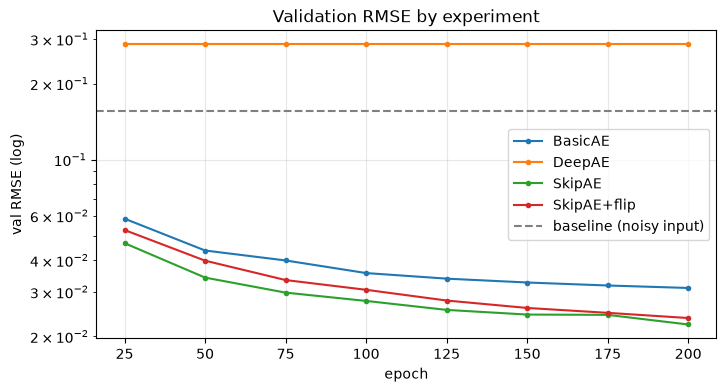

In [13]:
models = {"BasicAE": basic, "DeepAE": deep, "SkipAE": skip, "SkipAE+flip": skip_flip}
rows = [{"모델": "기준선(손상본 그대로)", "파라미터 수": 0, "검증 RMSE": round(base_rmse, 4), "PSNR(dB)": round(base_psnr, 2)}]
for name, model in models.items():
    rmse, psnr = evaluate(model, val_idx)
    rows.append({"모델": name, "파라미터 수": count_params(model), "검증 RMSE": round(rmse, 4), "PSNR(dB)": round(psnr, 2)})
display(pd.DataFrame(rows))

plt.figure(figsize=(8, 4))
for name, hist in results.items():
    plt.plot([e for e, _ in hist], [r for _, r in hist], marker="o", ms=3, label=name)
plt.axhline(base_rmse, color="gray", ls="--", label="baseline (noisy input)")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("val RMSE (log)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Validation RMSE by experiment"); plt.show()

**해석**

| 실험 | 검증 RMSE | 결과 |
| --- | --- | --- |
| BasicAE | 0.0311 | 기준 |
| A. DeepAE (깊이·채널 증가) | 0.2855 | **학습 실패** |
| B. SkipAE (스킵 커넥션) | **0.0223** | **가장 좋음** (BasicAE 대비 −28%) |
| C. SkipAE + 좌우 뒤집기 | 0.0236 | SkipAE보다 약간 나쁨 |

- **A. DeepAE:** RMSE가 200 epoch 내내 0.2855로, "모두 흰색" 기준선과 **정확히 같습니다**. train loss도 0.087에서 거의 줄지 않았습니다. 모델이 모든 픽셀을 흰색으로 내보내는 상태에 갇힌 것입니다. 배경이 대부분 흰색이라 "전부 흰색"이 손쉬운 출구가 되고, 층이 깊어 기울기가 앞쪽 층까지 잘 전달되지 않은 것으로 보입니다. (같은 구조를 다른 실행에서 돌렸을 때는 약 150 epoch 뒤에 빠져나온 적도 있어 시작값에 따라 달라집니다.) → **층을 늘린다고 자동으로 좋아지지는 않는다**는 결과입니다.
- **B. SkipAE:** 깊이는 DeepAE와 비슷한데 파라미터는 오히려 적습니다(123,754개 vs 165,761개). 그런데도 가장 좋았습니다. 인코더 특징과 입력 이미지를 디코더에 바로 넘겨 주니, 디코더는 "어디가 글자인지"를 다시 만들 필요 없이 **얼룩만 빼는 일**에 집중할 수 있습니다. 기울기도 이 지름길로 흘러서 DeepAE 같은 정체가 생기지 않았습니다.
- **C. 좌우 뒤집기:** 오히려 0.0013 나빠졌습니다. 뒤집힌 글자는 test에 나오지 않는 모양이라 도움이 되지 않은 것으로 보입니다. 게다가 256 무작위 자르기가 이미 매 epoch 다른 조각을 만들어 주고 있습니다.
- 그래프(로그 축)에서도 SkipAE(초록)가 모든 시점에서 가장 아래에 있고, 200 epoch에서도 아직 내려가는 중입니다.

### 6-2. 추가 실험 — 밝기·대비 증강, 수용 영역, U-Net, 채널 수

6-1 이후에도 오차가 남는 곳은 **진한 얼룩이 글자와 겹친 부분**과 **글자 경계**입니다. 이 두 곳을 겨냥해 네 가지를 더 실험합니다. 비교 대상은 6-1의 SkipAE(200 epoch, 검증 RMSE 0.0223)입니다.

| 실험 | 바꾼 것 | 기대 |
| --- | --- | --- |
| D. SkipAE + 밝기·대비 | 손상본만 `x ** g`로 변환합니다(g는 0.7~1.5에서 무작위). g < 1이면 밝아지고, g > 1이면 어두워지며 대비가 커집니다. | 더 진하거나 옅은 얼룩에도 견디기 |
| E. Skip3AE | 한 단계 더 줄여 1/8까지 내려갑니다(채널 32 → 64 → 128). | 수용 영역이 넓어져 큰 얼룩을 한 번에 보기 |
| F. UNetAE | 원래 크기·1/2·1/4 **단계마다** 인코더 특징을 디코더에 `torch.cat`으로 이어 붙입니다(맨 아래는 1/8). | 글자 경계를 단계별로 되살리기 |
| G. SkipAE (c=64) | 채널 수를 2배(32 → 64)로 늘립니다. | 표현력 증가 |

모델이 커지면 lr 0.001에서 학습이 불안정할 수 있습니다. 그래서 E·F·G는 **lr 0.001과 0.0003 두 가지**로 돌립니다. 성능이 lr을 낮춘 덕분인지 구조 덕분인지 구분하려고 **SkipAE도 lr 0.0003으로** 한 번 더 돌립니다.

In [ ]:
class Skip3AE(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(1, c, 3, 1, 1), nn.ReLU(),
                                  nn.Conv2d(c, c, 3, 2, 1), nn.ReLU())                 # (B,32,H/2,W/2)
        self.enc2 = nn.Sequential(nn.Conv2d(c, 2 * c, 3, 1, 1), nn.ReLU(),
                                  nn.Conv2d(2 * c, 2 * c, 3, 2, 1), nn.ReLU())         # (B,64,H/4,W/4)
        self.enc3 = nn.Sequential(nn.Conv2d(2 * c, 4 * c, 3, 1, 1), nn.ReLU(),
                                  nn.Conv2d(4 * c, 4 * c, 3, 2, 1), nn.ReLU())         # (B,128,H/8,W/8) 한 단계 더
        self.dec3 = nn.Sequential(nn.ConvTranspose2d(4 * c, 2 * c, 4, 2, 1), nn.ReLU())  # (B,64,H/4,W/4)
        self.dec2 = nn.Sequential(nn.Conv2d(2 * c, 2 * c, 3, 1, 1), nn.ReLU(),
                                  nn.ConvTranspose2d(2 * c, c, 4, 2, 1), nn.ReLU())    # (B,32,H/2,W/2)
        self.dec1 = nn.Sequential(nn.Conv2d(c, c, 3, 1, 1), nn.ReLU(),
                                  nn.ConvTranspose2d(c, c, 4, 2, 1), nn.ReLU())        # (B,32,H,W)
        self.out = nn.Sequential(nn.Conv2d(c + 1, 1, 3, 1, 1), nn.Sigmoid())           # (B,1,H,W)
    def forward(self, x):
        H, W = x.shape[2], x.shape[3]
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)                                          # 258 → 129 → 65 → 33
        d3 = self.dec3(e3)[:, :, :e2.shape[2], :e2.shape[3]]        # 33 → 66 → 65로 자르기
        d2 = self.dec2(d3 + e2)[:, :, :e1.shape[2], :e1.shape[3]]   # 65 → 130 → 129로 자르기
        d1 = self.dec1(d2 + e1)[:, :, :H, :W]                       # 129 → 258
        return self.out(torch.cat([d1, x], dim=1))

class UNetAE(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(1, c, 3, 1, 1), nn.ReLU(),
                                  nn.Conv2d(c, c, 3, 1, 1), nn.ReLU())                 # (B,32,H,W)       크기 유지
        self.enc2 = nn.Sequential(nn.Conv2d(c, 2 * c, 3, 2, 1), nn.ReLU(),
                                  nn.Conv2d(2 * c, 2 * c, 3, 1, 1), nn.ReLU())         # (B,64,H/2,W/2)
        self.enc3 = nn.Sequential(nn.Conv2d(2 * c, 4 * c, 3, 2, 1), nn.ReLU(),
                                  nn.Conv2d(4 * c, 4 * c, 3, 1, 1), nn.ReLU())         # (B,128,H/4,W/4)
        self.mid = nn.Sequential(nn.Conv2d(4 * c, 4 * c, 3, 2, 1), nn.ReLU())          # (B,128,H/8,W/8)  가장 압축된 z
        self.up3 = nn.Sequential(nn.ConvTranspose2d(4 * c, 4 * c, 4, 2, 1), nn.ReLU())  # (B,128,H/4,W/4)
        self.dec3 = nn.Sequential(nn.Conv2d(8 * c, 2 * c, 3, 1, 1), nn.ReLU())         # cat (B,256) → (B,64,H/4,W/4)
        self.up2 = nn.Sequential(nn.ConvTranspose2d(2 * c, 2 * c, 4, 2, 1), nn.ReLU())  # (B,64,H/2,W/2)
        self.dec2 = nn.Sequential(nn.Conv2d(4 * c, c, 3, 1, 1), nn.ReLU())             # cat (B,128) → (B,32,H/2,W/2)
        self.up1 = nn.Sequential(nn.ConvTranspose2d(c, c, 4, 2, 1), nn.ReLU())          # (B,32,H,W)
        self.dec1 = nn.Sequential(nn.Conv2d(2 * c, c, 3, 1, 1), nn.ReLU())             # cat (B,64) → (B,32,H,W)
        self.out = nn.Sequential(nn.Conv2d(c + 1, 1, 3, 1, 1), nn.Sigmoid())           # cat (B,33) → (B,1,H,W)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        m = self.mid(e3)
        u3 = self.up3(m)[:, :, :e3.shape[2], :e3.shape[3]]          # 홀수 크기에서 넘친 칸 자르기
        d3 = self.dec3(torch.cat([u3, e3], dim=1))                  # 스킵: 1/4 단계
        u2 = self.up2(d3)[:, :, :e2.shape[2], :e2.shape[3]]
        d2 = self.dec2(torch.cat([u2, e2], dim=1))                  # 스킵: 1/2 단계
        u1 = self.up1(d2)[:, :, :e1.shape[2], :e1.shape[3]]
        d1 = self.dec1(torch.cat([u1, e1], dim=1))                  # 스킵: 원래 크기 단계
        return self.out(torch.cat([d1, x], dim=1))                  # 스킵: 입력 이미지

for name, m in [("Skip3AE", Skip3AE()), ("UNetAE", UNetAE()), ("SkipAE(c=64)", SkipAE(c=64))]:
    print(name, "파라미터 수:", count_params(m))
    check_shapes(m)

Skip3AE 파라미터 수: 513258
  입력 (1, 1, 256, 256) → 출력 (1, 1, 256, 256)
  입력 (1, 1, 420, 540) → 출력 (1, 1, 420, 540)
  입력 (1, 1, 258, 540) → 출력 (1, 1, 258, 540)
UNetAE 파라미터 수: 981482
  입력 (1, 1, 256, 256) → 출력 (1, 1, 256, 256)
  입력 (1, 1, 420, 540) → 출력 (1, 1, 420, 540)
  입력 (1, 1, 258, 540) → 출력 (1, 1, 258, 540)
SkipAE(c=64) 파라미터 수: 493258
  입력 (1, 1, 256, 256) → 출력 (1, 1, 256, 256)
  입력 (1, 1, 420, 540) → 출력 (1, 1, 420, 540)
  입력 (1, 1, 258, 540) → 출력 (1, 1, 258, 540)


In [15]:
results2 = {}
models2 = {}
runs = [("D. SkipAE+밝기·대비", SkipAE, {}, 1e-3, True),
        ("E. Skip3AE lr0.001", Skip3AE, {}, 1e-3, False),
        ("F. UNetAE lr0.001", UNetAE, {}, 1e-3, False),
        ("G. SkipAE(c=64) lr0.001", SkipAE, {"c": 64}, 1e-3, False),
        ("SkipAE lr0.0003", SkipAE, {}, 3e-4, False),
        ("E. Skip3AE lr0.0003", Skip3AE, {}, 3e-4, False),
        ("F. UNetAE lr0.0003", UNetAE, {}, 3e-4, False),
        ("G. SkipAE(c=64) lr0.0003", SkipAE, {"c": 64}, 3e-4, False)]
for name, M, kw, lr, g in runs:
    print("▶", name)
    torch.manual_seed(SEED)
    models2[name], results2[name] = train_model(M(**kw), EPOCHS, lr=lr, gamma=g)

▶ D. SkipAE+밝기·대비
epoch  100  train loss 0.00139  val RMSE 0.0323  PSNR 29.82 dB  (27s)
epoch  200  train loss 0.00091  val RMSE 0.0282  PSNR 31.00 dB  (54s)
▶ E. Skip3AE lr0.001
epoch  100  train loss 0.08761  val RMSE 0.2855  PSNR 10.89 dB  (32s)
epoch  200  train loss 0.08712  val RMSE 0.2855  PSNR 10.89 dB  (64s)
▶ F. UNetAE lr0.001
epoch  100  train loss 0.08761  val RMSE 0.2855  PSNR 10.89 dB  (65s)
epoch  200  train loss 0.08712  val RMSE 0.2855  PSNR 10.89 dB  (131s)
▶ G. SkipAE(c=64) lr0.001
epoch  100  train loss 0.08761  val RMSE 0.2855  PSNR 10.89 dB  (64s)
epoch  200  train loss 0.00107  val RMSE 0.0308  PSNR 30.24 dB  (127s)
▶ SkipAE lr0.0003
epoch  100  train loss 0.00163  val RMSE 0.0373  PSNR 28.57 dB  (27s)
epoch  200  train loss 0.00095  val RMSE 0.0292  PSNR 30.69 dB  (54s)
▶ E. Skip3AE lr0.0003
epoch  100  train loss 0.00117  val RMSE 0.0333  PSNR 29.55 dB  (32s)
epoch  200  train loss 0.00078  val RMSE 0.0273  PSNR 31.28 dB  (64s)
▶ F. UNetAE lr0.0003
epoch  100  

,모델,파라미터 수,검증 RMSE,PSNR(dB)
0,SkipAE lr0.001 (6-1 최고),123754,0.0223,33.03
1,D. SkipAE+밝기·대비,123754,0.0282,31.00
2,E. Skip3AE lr0.001,513258,0.2855,10.89
3,F. UNetAE lr0.001,981482,0.2855,10.89
4,G. SkipAE(c=64) lr0.001,493258,0.0308,30.23
5,SkipAE lr0.0003,123754,0.0292,30.69
6,E. Skip3AE lr0.0003,513258,0.0273,31.28
7,F. UNetAE lr0.0003,981482,0.0186,34.61
8,G. SkipAE(c=64) lr0.0003,493258,0.0218,33.23


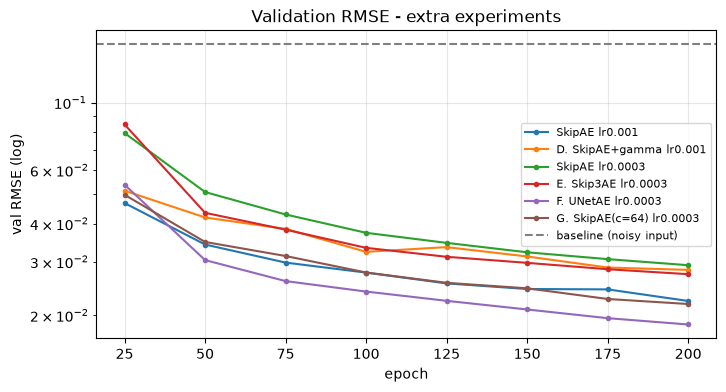

In [16]:
rows = [{"모델": "SkipAE lr0.001 (6-1 최고)", "파라미터 수": count_params(skip), "검증 RMSE": round(evaluate(skip, val_idx)[0], 4)}]
for name, model in models2.items():
    rows.append({"모델": name, "파라미터 수": count_params(model), "검증 RMSE": round(evaluate(model, val_idx)[0], 4)})
table2 = pd.DataFrame(rows)
table2["PSNR(dB)"] = [round(20 * math.log10(1 / r), 2) for r in table2["검증 RMSE"]]
display(table2)

plt.figure(figsize=(8, 4))
plt.plot([e for e, _ in results["SkipAE"]], [r for _, r in results["SkipAE"]], marker="o", ms=3, label="SkipAE lr0.001")
for name, hist in results2.items():
    if "0.0003" in name or "밝기" in name:
        label = name.replace("D. SkipAE+밝기·대비", "D. SkipAE+gamma lr0.001")
        plt.plot([e for e, _ in hist], [r for _, r in hist], marker="o", ms=3, label=label)
plt.axhline(base_rmse, color="gray", ls="--", label="baseline (noisy input)")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("val RMSE (log)"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.title("Validation RMSE - extra experiments"); plt.show()

**해석**

| 실험 | lr 0.001 | lr 0.0003 | 6-1 SkipAE(0.0223)와 비교 |
| --- | --- | --- | --- |
| SkipAE (비교 기준) | 0.0223 | 0.0292 | – |
| D. SkipAE + 밝기·대비 | 0.0282 | – | 나빠짐 |
| E. Skip3AE (한 단계 더) | 0.2855 (실패) | 0.0273 | 나빠짐 |
| F. **UNetAE** | 0.2855 (실패) | **0.0186** | **17% 좋아짐 (가장 좋음)** |
| G. SkipAE (c=64) | 0.0308 | 0.0218 | 거의 같음 |

- **D. 밝기·대비 증강:** 0.0223 → 0.0282로 오히려 나빠졌습니다. 진한 얼룩을 흉내 내려던 의도였지만, 이 데이터는 train과 test의 밝기 분포가 이미 비슷합니다. 그런 상태에서 손상본만 밝기를 바꾸니, 모델이 "실제로는 나오지 않는 밝기"까지 맞추느라 학습이 어려워진 것으로 보입니다. 좌우 뒤집기(6-1)와 같은 결론입니다. 증강은 test에 실제로 나올 변형이어야 효과가 있습니다.
- **lr 0.001에서의 실패:** 파라미터가 50만 개 이상인 큰 모델 셋(E·F·G)은 모두 처음에 "모두 흰색" 상태(0.2855)에 갇혔습니다. DeepAE(6-1)와 같은 현상입니다. G는 200 epoch 근처에서 빠져나왔지만 늦었습니다. **lr을 0.0003으로 낮추자 셋 다 정상적으로 학습되었습니다.** 큰 모델은 한 번의 갱신 폭이 커서, 출력이 Sigmoid의 1 쪽으로 쏠리면 돌아오지 못한 것으로 보입니다.
- **lr 효과와 구조 효과 구분:** 같은 lr 0.0003에서 SkipAE는 0.0292로 오히려 나빠졌습니다(작은 모델에게는 학습이 느려짐). 그런데 UNetAE는 0.0186입니다. 따라서 UNetAE가 좋아진 것은 **lr 덕분이 아니라 구조 덕분**입니다.
- **E. 수용 영역 넓히기:** 같은 lr 0.0003에서 SkipAE(0.0292)보다는 좋습니다(0.0273). 하지만 lr 0.001의 SkipAE(0.0223)보다는 나쁩니다. 1/8까지 줄였는데 스킵이 덧셈 두 개뿐이라, 늘어난 수용 영역보다 줄이면서 잃은 위치 정보의 손해가 더 컸던 것으로 보입니다.
- **F. U-Net 형태:** 같은 1/8 깊이인데 **단계마다 이어 붙이기(cat)** 를 하자 가장 좋아졌습니다. 아래쪽 단계는 넓은 영역을 보고 "어디가 얼룩인지"를 판단합니다. 위쪽 단계는 이어 붙인 원래 해상도 특징으로 "글자 경계"를 되살립니다. 두 역할이 나뉜 것입니다.
- **G. 채널 2배:** 파라미터가 4배(123,754 → 493,258)인데 0.0223 → 0.0218로 거의 같습니다. 이 문제에서는 **채널 수보다 정보가 흐르는 길(구조)이 더 중요**했습니다.
- 그래프에서도 UNetAE(보라)가 모든 시점에서 가장 아래에 있고, 200 epoch에서도 아직 내려가는 중입니다.
- 참고: 표의 PSNR은 반올림한 RMSE로 계산해서 학습 로그 값과 0.01~0.02 dB 차이가 납니다.

## 7. 최종 모델

6-2에서 가장 좋았던 **UNetAE(lr 0.0003)** 를 골라 600 epoch까지 학습합니다. 200 epoch에서도 검증 RMSE가 계속 내려가고 있었기 때문입니다.

In [17]:
torch.manual_seed(SEED)
final, hist_final = train_model(UNetAE(), 600, lr=3e-4)
final_rmse, final_psnr = evaluate(final, val_idx)
print(f"\n최종 검증 RMSE {final_rmse:.4f}  PSNR {final_psnr:.2f} dB  (기준선 {base_rmse:.4f} / {base_psnr:.2f} dB)")
torch.save(final.state_dict(), "unet_ae_final.pt")

epoch  100  train loss 0.00060  val RMSE 0.0239  PSNR 32.43 dB  (66s)
epoch  200  train loss 0.00039  val RMSE 0.0186  PSNR 34.59 dB  (132s)
epoch  300  train loss 0.00038  val RMSE 0.0159  PSNR 35.98 dB  (198s)
epoch  400  train loss 0.00017  val RMSE 0.0143  PSNR 36.88 dB  (264s)
epoch  500  train loss 0.00016  val RMSE 0.0134  PSNR 37.43 dB  (332s)
epoch  600  train loss 0.00022  val RMSE 0.0128  PSNR 37.89 dB  (400s)

최종 검증 RMSE 0.0128  PSNR 37.89 dB  (기준선 0.1551 / 16.19 dB)


**해석**
- 600 epoch 동안 검증 RMSE가 0.0239(100) → 0.0186(200) → 0.0159(300) → 0.0143(400) → 0.0134(500) → **0.0128**(600)으로 계속 줄었습니다.
- 최종 **RMSE 0.0128, PSNR 37.89 dB**입니다. 기준선 0.1551보다 약 92% 줄었습니다.
- 학습은 GPU에서 약 6.5분(395초) 걸렸습니다. SkipAE보다 파라미터가 약 8배 많아 느립니다.
- 주의: 500 → 600 구간에서도 0.0006 줄어 아직 여지가 있습니다. 다만 같은 검증 24장으로 모델과 epoch를 골랐기 때문에, 이 점수는 실제 test 점수보다 약간 낙관적일 수 있습니다.

## 8. 복원 결과 시각화

### 8-1. 이미지별 개선량

> 개선량 = 기준선 RMSE − 복원 RMSE (이미지별). 개선량 > 0이면 개선입니다.

In [18]:
per_image = []
for i in val_idx:
    b, _ = rmse_psnr([noisy[i]], [clean[i]])
    r, _ = rmse_psnr([predict(final, noisy[i])], [clean[i]])
    per_image.append({"파일": train_files[i], "크기": noisy[i].shape, "기준선 RMSE": round(b, 4), "복원 RMSE": round(r, 4), "개선량": round(b - r, 4)})
per_image = pd.DataFrame(per_image).sort_values("복원 RMSE", ascending=False)
print("개선된 이미지:", (per_image["개선량"] > 0).sum(), "/", len(per_image))
display(per_image.head(5))
display(per_image.tail(3))

개선된 이미지: 24 / 24


,파일,크기,기준선 RMSE,복원 RMSE,개선량
21,168.png,"(420, 540)",0.1462,0.0182,0.1280
9,60.png,"(258, 540)",0.1524,0.0180,0.1344
12,155.png,"(420, 540)",0.1470,0.0163,0.1307
13,215.png,"(420, 540)",0.1494,0.0158,0.1336
0,180.png,"(420, 540)",0.1483,0.0154,0.1330


,파일,크기,기준선 RMSE,복원 RMSE,개선량
17,98.png,"(420, 540)",0.1639,0.0105,0.1534
18,140.png,"(420, 540)",0.1995,0.0095,0.1900
4,81.png,"(420, 540)",0.1452,0.0092,0.1361


**해석**
- 검증 **24장 모두** 손상본보다 좋아졌습니다(개선량 > 0). 평균만 좋아진 것이 아니라 모든 이미지에서 효과가 있었습니다.
- 가장 덜 복원된 168.png도 0.1462 → 0.0182로 크게 개선되었습니다. 덜 복원된 5장 중 4장은 높이 420, 1장(60.png)은 높이 258이어서 **두 크기 모두에서 문제없이** 동작합니다.
- 가장 잘 복원된 81.png는 0.0092입니다. 140.png는 기준선이 0.1995로 가장 심하게 손상된 이미지 중 하나였는데도 0.0095까지 내려가, 개선량(0.1900)이 가장 컸습니다.

### 8-2. 손상 / 복원 / 원본 비교

가장 잘 복원된 이미지와 가장 덜 복원된 이미지를 나란히 놓고, 복원과 원본의 차이(|복원 − 원본|)도 함께 봅니다. 차이 그림은 밝을수록 오차가 큽니다.

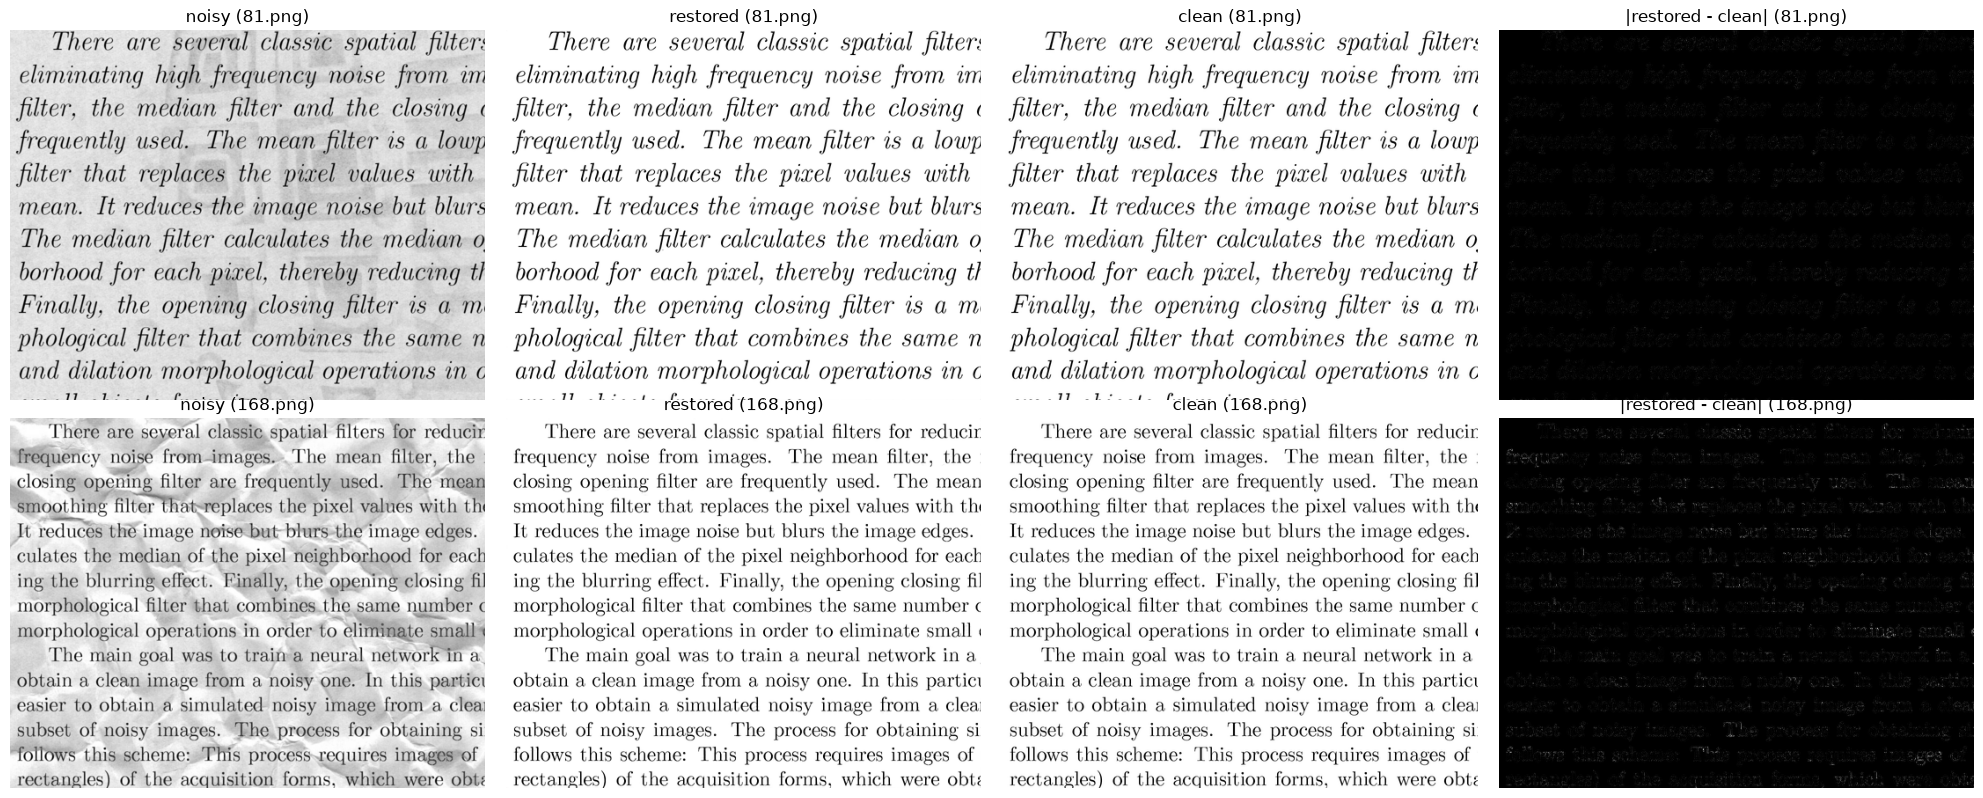

In [19]:
worst = train_files.index(per_image.iloc[0]["파일"])
best = train_files.index(per_image.iloc[-1]["파일"])
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for row, i in enumerate([best, worst]):
    rec = predict(final, noisy[i])
    for ax, img, title in zip(axes[row], [noisy[i], rec, clean[i], np.abs(rec - clean[i])],
                              ["noisy", "restored", "clean", "|restored - clean|"]):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1 if title != "|restored - clean|" else 0.5)
        ax.set_title(f"{title} ({train_files[i]})"); ax.axis("off")
plt.tight_layout(); plt.show()

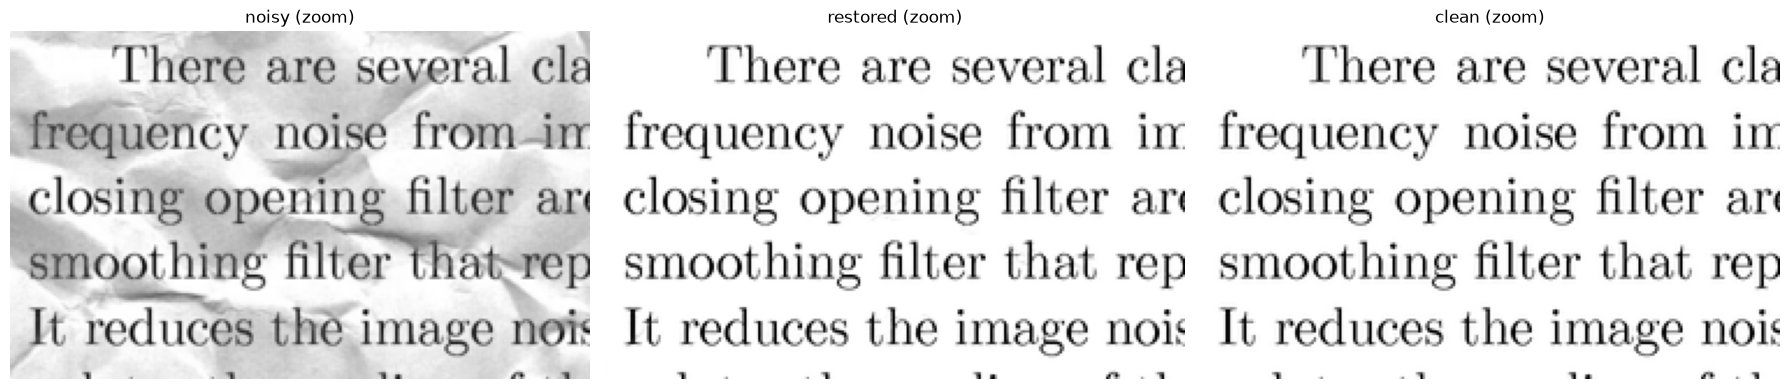

In [20]:
# 글자 부분을 확대해 보기 (가장 덜 복원된 이미지의 왼쪽 위 150×250 영역)
i = worst
rec = predict(final, noisy[i])
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, img, title in zip(axes, [noisy[i], rec, clean[i]], ["noisy", "restored", "clean"]):
    ax.imshow(img[:150, :250], cmap="gray", vmin=0, vmax=1); ax.set_title(f"{title} (zoom)"); ax.axis("off")
plt.tight_layout(); plt.show()

**해석**
- **배경:** 81.png의 줄무늬 얼룩과 168.png의 구김 질감이 복원본에서는 거의 사라져, 원본처럼 흰 배경이 되었습니다.
- **오차 그림:** 배경은 거의 검은색(오차 0)이고, 남은 오차는 **글자 획의 가장자리**에 몰려 있습니다. 확대 그림에서도 글자 모양은 잘 살아 있습니다. 다만 가장자리가 원본보다 아주 조금 흐립니다. 168.png는 글자가 작고 촘촘해 경계 픽셀의 비율이 높고, 그래서 RMSE가 상대적으로 높게 나온 것으로 보입니다.
- 즉 지금 모델의 한계는 "얼룩 제거"보다 "**글자 경계를 날카롭게 복원**하는 것"에 있습니다.

## 9. 테스트 예측과 제출 파일

### 9-1. 테스트 이미지 복원

예측 크기 == 입력 크기: True


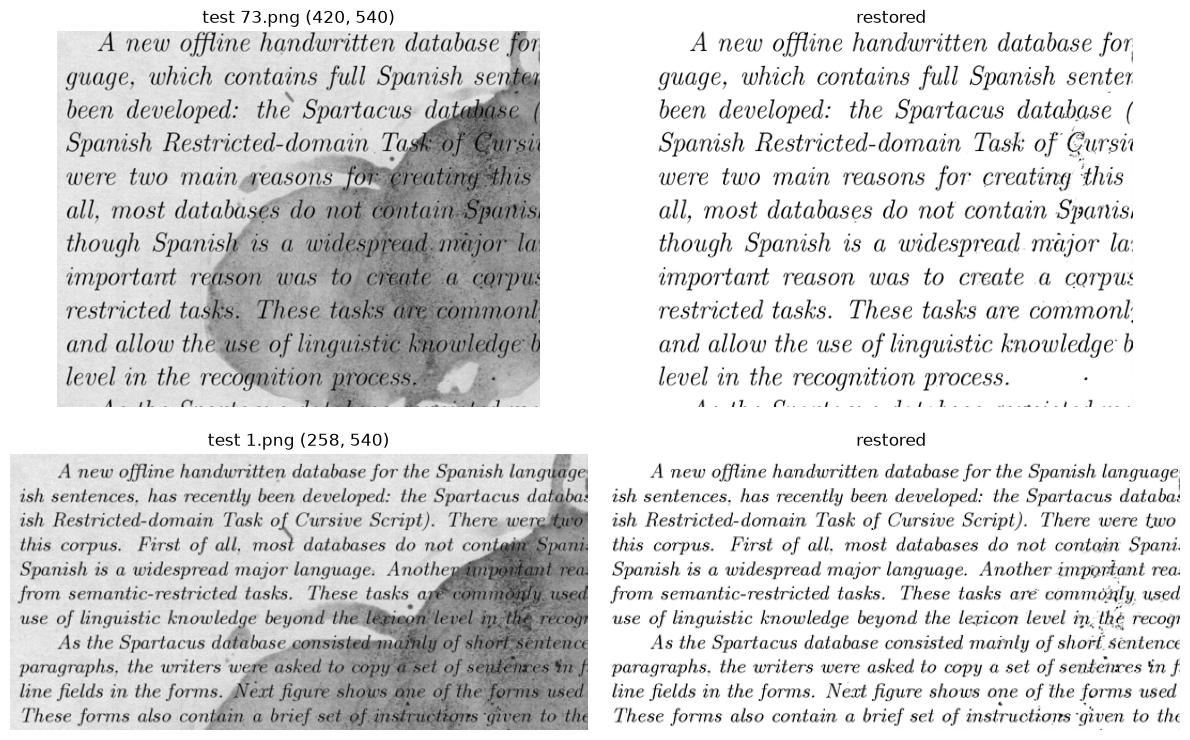

In [21]:
test_preds = [predict(final, img) for img in test_imgs]
print("예측 크기 == 입력 크기:", all(p.shape == t.shape for p, t in zip(test_preds, test_imgs)))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
show_k = [[j for j, t in enumerate(test_imgs) if t.shape[0] == h][0] for h in (420, 258)]   # 큰 것 1장 + 작은 것 1장
for row, k in enumerate(show_k):
    axes[row, 0].imshow(test_imgs[k], cmap="gray", vmin=0, vmax=1); axes[row, 0].set_title(f"test {test_files[k]} {test_imgs[k].shape}")
    axes[row, 1].imshow(test_preds[k], cmap="gray", vmin=0, vmax=1); axes[row, 1].set_title("restored")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

### 9-2. 제출 파일 만들기

- `sampleSubmission.csv`의 id는 `이미지번호_행_열`(1부터 시작)이고 값은 0~1 픽셀값입니다.
- 순서는 이미지 번호를 **문자열 순서**("1", "10", "100", …)로 놓고, 한 이미지 안에서는 **행이 먼저 바뀝니다**(1_1_1, 1_2_1, …). 같은 순서로 만들고, 예시 파일과 id가 완전히 같은지 확인합니다.

In [22]:
lines = ["id,value"]
for f in sorted(test_files, key=lambda f: f[:-4]):          # "1", "10", "100" ... 문자열 순서
    k = test_files.index(f)
    img_id, pred = f[:-4], test_preds[k]
    H, W = pred.shape
    for col in range(W):
        for row in range(H):                                 # 행이 먼저 바뀜
            lines.append(f"{img_id}_{row + 1}_{col + 1},{pred[row, col]:.4f}")
with open("submission.csv", "w") as fp:
    fp.write("\n".join(lines) + "\n")
print("제출 행 수:", len(lines) - 1)

sample_path = os.path.join(DATA_DIR, "sampleSubmission.csv")
if os.path.exists(sample_path):
    sample = pd.read_csv(sample_path)
    sub = pd.read_csv("submission.csv")
    print("예시와 행 수 같음:", len(sub) == len(sample), "/ id 순서까지 같음:", (sub["id"] == sample["id"]).all())
    print("값 범위:", sub["value"].min(), "~", sub["value"].max())
    display(sub.head())

제출 행 수: 14230080
예시와 행 수 같음: True / id 순서까지 같음: True
값 범위: 0.0001 ~ 1.0


,id,value
0,1_1_1,0.9840
1,1_2_1,0.9983
2,1_3_1,0.9993
3,1_4_1,0.9993
4,1_5_1,0.9993


**해석**
- 테스트 72장 모두 **입력과 같은 크기**(420×540, 258×540)로 복원되었습니다.
- 큰 얼룩(73.png, 1.png)은 대부분 지워졌습니다. 하지만 **얼룩이 글자와 겹치던 곳에는 여전히 작은 점 잡음이 남아 있습니다**("Cursive", "important", "commonly" 주변). U-Net으로 바꿔도 이 부분은 눈에 띄게 줄지 않았습니다. 학습 데이터에 진한 얼룩이 글자와 겹친 경우가 적었던 것으로 보입니다.
- 제출 파일은 14,230,080행이고, `sampleSubmission.csv`와 **id 순서까지 똑같습니다**. 값은 0.0001~1.0으로 0~1 범위 안에 있습니다.

**Kaggle 제출 점수 (RMSE)**

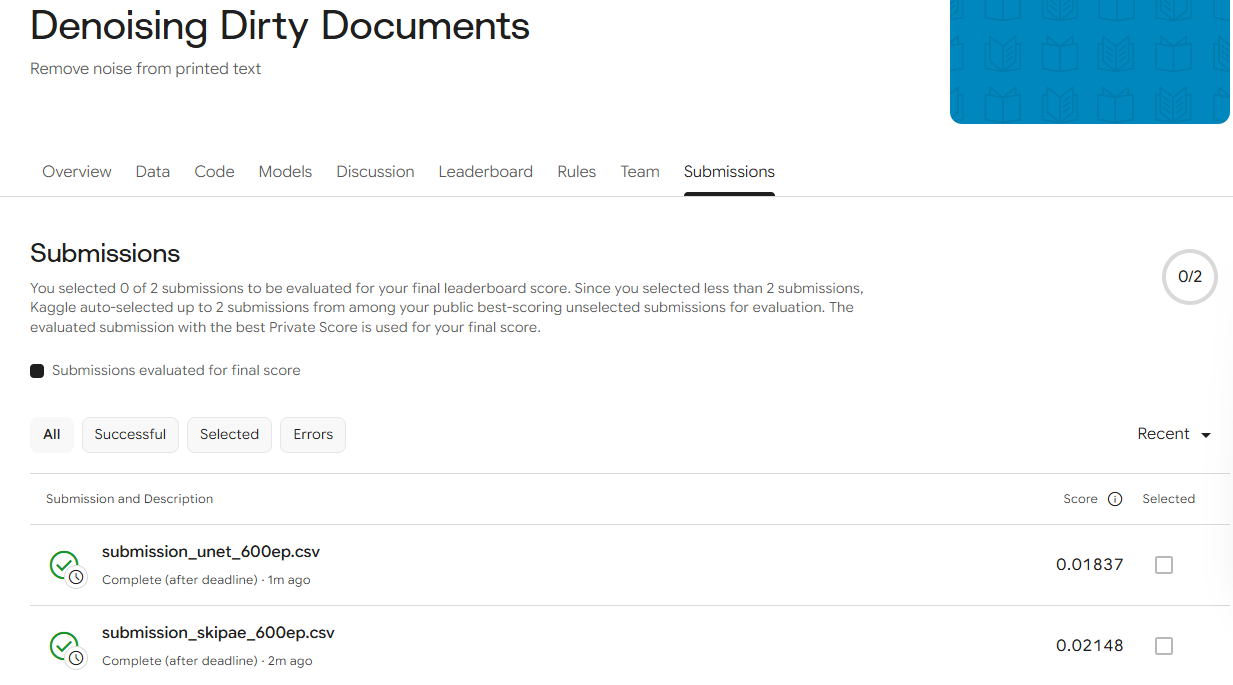

| 제출 파일 | 모델 | 검증 RMSE | Kaggle 점수 | 
| --- | --- | --- | --- |
| `submission_skipae_600ep.csv` | SkipAE 600 epoch | 0.0150 | 0.02148 | 
| `submission_unet_600ep.csv` | **UNetAE 600 epoch** | **0.0128** | **0.01837** | 




- Kaggle에서도 UNetAE가 SkipAE보다 오차가 **약 14% 작았습니다**. 검증에서 본 개선(약 15%)이 test에서도 거의 그대로 나타났으므로, 모델 선택은 맞았습니다.
- 두 모델 모두 Kaggle 점수가 검증 점수보다 **약 1.4배 나쁩니다**. 같은 검증 24장으로 모델과 epoch를 골랐기 때문에 검증 점수가 낙관적이었습니다. 위에서 본 점 잡음처럼, 학습 데이터에 드문 얼룩이 test에 더 있었던 것도 원인으로 보입니다.
- 두 모델의 비율이 거의 같으므로, 검증 점수는 절대값은 낙관적이어도 **모델 간 순서를 정하는 데는 믿을 만했습니다.**

## 10. 정리

### 결과
| 단계 | 검증 RMSE | PSNR | Kaggle 점수 |
| --- | --- | --- | --- |
| 기준선(손상본) | 0.1551 | 16.19 dB | – |
| BasicAE 200 epoch | 0.0311 | 30.15 dB | – |
| SkipAE 200 epoch | 0.0223 | 33.05 dB | – |
| UNetAE 200 epoch (lr 0.0003) | 0.0186 | 34.59 dB | – |
| SkipAE 600 epoch | 0.0150 | 36.45 dB | 0.02148 |
| **UNetAE 600 epoch (최종)** | **0.0128** | **37.89 dB** | **0.01837** |

### 배운 점
1. **크기 문제:** stride 2를 두 번 쓰면 높이 258이 260으로 돌아옵니다. 크기를 바꾸지 않고 **256 조각으로 학습한 뒤 출력을 자르는 방식**으로 해결했습니다. 원래 해상도를 그대로 쓰니 제출용 픽셀 값도 그대로 쓸 수 있었습니다.
2. **깊이와 학습률:** 층이나 채널만 늘린 큰 모델은 lr 0.001에서 "모두 흰색" 상태에 갇혔습니다(DeepAE, Skip3AE, UNetAE, c=64). lr을 0.0003으로 낮추자 학습이 되었습니다. **모델이 커지면 학습률도 함께 조정해야 합니다.**
3. **스킵 커넥션:** 가장 효과가 컸습니다. 덧셈 스킵(SkipAE)으로 0.0311 → 0.0223이 되었고, 단계마다 이어 붙이는 U-Net 형태로 0.0186까지 내려갔습니다. 같은 lr에서 SkipAE는 0.0292였으니, 이 개선은 구조 덕분입니다.
4. **채널 수:** 2배로 늘려도(파라미터 4배) 거의 같았습니다. 크기보다 **정보가 흐르는 길**이 중요했습니다.
5. **데이터 증강:** 좌우 뒤집기(0.0236)와 밝기·대비 변환(0.0282) 모두 효과가 없었습니다. 증강은 "test에 실제로 나올 변형"이어야 합니다.


## (심화) ECG5000 이상 탐지: LSTM 오토인코더

정상 심전도 신호만으로 LSTM 오토인코더를 학습시킵니다. 그 뒤 **복원 오차가 큰 신호를 이상 심박으로** 판정합니다.
정상 패턴만 배운 모델은 처음 보는 이상 패턴을 잘 복원하지 못한다는 오토인코더의 원리를 실제 데이터로 확인해보기.

| 항목 | 내용 |
| --- | --- |
| 데이터 | ECG5000, 신호 4,998개, 신호 하나 = 140 타임스텝, 마지막 열 = 라벨(1 정상, 0 이상) |
| 학습 | train의 정상 신호만 사용 |
| 판정 | 복원 오차(MSE) > 임계값 → 이상 |
| 평가 | test 전체(정상 + 이상)에서 Precision, Recall, F1. 이상을 양성(1) 으로 봅니다 |

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

SEED = 0
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

df = pd.read_csv("http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X_all = df.iloc[:, :-1].values.astype(np.float32)     # (4998, 140)
labels = df.iloc[:, -1].values.astype(int)            # 1 정상, 0 이상
print("데이터 shape:", X_all.shape)
print("정상:", (labels == 1).sum(), "/ 이상:", (labels == 0).sum())

데이터 shape: (4998, 140)
정상: 2919 / 이상: 2079


In [ ]:
X_tr, X_te, lab_tr, lab_te = train_test_split(X_all, labels, test_size=0.2, random_state=SEED, stratify=labels)

lo, hi = X_tr.min(), X_tr.max()
X_tr = (X_tr - lo) / (hi - lo)
X_te = (X_te - lo) / (hi - lo)

normal_tr = X_tr[lab_tr == 1]                         # 학습에는 정상만
y_te = (lab_te == 0).astype(int)                      # 평가용: 이상 = 1(양성)
print("학습용 정상 신호:", normal_tr.shape)
print("test:", X_te.shape, "/ 그중 이상:", y_te.sum())
print(f"정규화 기준 min {lo:.3f}, max {hi:.3f}")

학습용 정상 신호: (2335, 140)
test: (1000, 140) / 그중 이상: 416
정규화 기준 min -7.090, max 7.402


**해석**
- 전체 4,998개 중 정상은 2,919개(58%), 이상은 2,079개(42%)입니다. `stratify`로 나눠 train과 test의 비율을 같게 맞췄습니다.
- 학습에는 train 중 **정상 신호만** 씁니다. 이상 신호를 학습에 넣으면 모델이 이상 패턴까지 잘 복원하게 되어 구분이 어려워집니다.
- 정규화 기준(min, max)도 train에서만 구했습니다. test 값을 보고 기준을 정하면 test 정보가 학습에 새어 들어갑니다.

In [4]:
class LSTMAE(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.encoder = nn.LSTM(1, hidden, batch_first=True)
        self.decoder = nn.LSTM(1, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):                             # x: (B, 140, 1)
        _, (h_n, c_n) = self.encoder(x)               # h_n: (1, B, H) = 신호 전체를 요약한 잠재 벡터
        zeros = torch.zeros(x.shape[0], x.shape[1], 1, device=x.device)   # 디코더 입력은 0, 정보는 초기 상태로만 전달
        output, _ = self.decoder(zeros, (h_n, c_n))   # (B, 140, H)
        return self.out(output)                       # (B, 140, 1)

demo = LSTMAE()
xb = torch.tensor(normal_tr[:4]).unsqueeze(-1)        # (4, 140, 1)
_, (h_demo, _) = demo.encoder(xb)
print("입력:", tuple(xb.shape), "→ 잠재 벡터 h_n:", tuple(h_demo.shape), "→ 출력:", tuple(demo(xb).shape))
print("파라미터 수:", sum(p.numel() for p in demo.parameters()))

입력: (4, 140, 1) → 잠재 벡터 h_n: (1, 4, 64) → 출력: (4, 140, 1)
파라미터 수: 34369


**구조**
- **인코더 LSTM**이 140개 시점을 차례로 읽고, 마지막 hidden state `h_n`(크기 64)에 신호 전체를 요약합니다. 이것이 잠재 벡터입니다.
- **디코더 LSTM**은 `h_n`, `c_n`을 초기 상태로 받아 140개 시점을 다시 만들어 냅니다. 디코더 입력은 모두 0입니다. 그래서 원래 신호의 정보는 **잠재 벡터를 통해서만** 전달됩니다. 입력을 그대로 베끼는 지름길이 없습니다.
- 마지막 `Linear`가 각 시점의 hidden(64)을 값 1개로 바꿉니다.

epoch  25  train loss 0.00229


epoch  50  train loss 0.00218


epoch  75  train loss 0.00109


epoch 100  train loss 0.00072


epoch 125  train loss 0.00060


epoch 150  train loss 0.00055


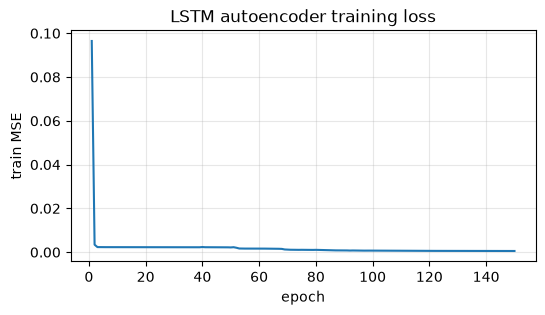

In [5]:
def recon_errors(model, X):
    model.eval()
    with torch.no_grad():
        x = torch.tensor(X).unsqueeze(-1).to(device)
        return ((model(x) - x) ** 2).mean(dim=(1, 2)).cpu().numpy()   # 신호마다 MSE 하나

torch.manual_seed(SEED)
ecg_model = LSTMAE().to(device)
optimizer = torch.optim.Adam(ecg_model.parameters(), lr=1e-3)
loader = DataLoader(torch.tensor(normal_tr).unsqueeze(-1), batch_size=64, shuffle=True)
ecg_hist = []
for epoch in range(1, 151):
    ecg_model.train()
    total = 0
    for xb in loader:
        xb = xb.to(device)
        optimizer.zero_grad()
        loss = nn.MSELoss()(ecg_model(xb), xb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    ecg_hist.append(total / len(normal_tr))
    if epoch % 25 == 0:
        print(f"epoch {epoch:3d}  train loss {ecg_hist[-1]:.5f}")

plt.figure(figsize=(6, 3))
plt.plot(range(1, len(ecg_hist) + 1), ecg_hist)
plt.xlabel("epoch"); plt.ylabel("train MSE"); plt.title("LSTM autoencoder training loss"); plt.grid(alpha=0.3)
plt.show()

**해석**
- train loss가 첫 epoch 약 0.1에서 150 epoch 0.00055까지 줄었습니다.
- 그래프에서는 첫 epoch 값이 커서 뒤가 평평해 보입니다. 실제로는 25 epoch 0.00229 → 75 epoch 0.00109 → 150 epoch 0.00055로 계속 줄었습니다.
- 50~75 epoch 사이에서 한 번 크게 내려갑니다. 이 시점부터 모델이 평균적인 모양을 넘어 신호의 세부 모양까지 따라가기 시작한 것으로 보입니다.

임계값(train 정상 오차의 95번째 백분위수): 0.00168


평균 복원 오차  train 정상 0.00060 / test 정상 0.00059 / test 이상 0.00341


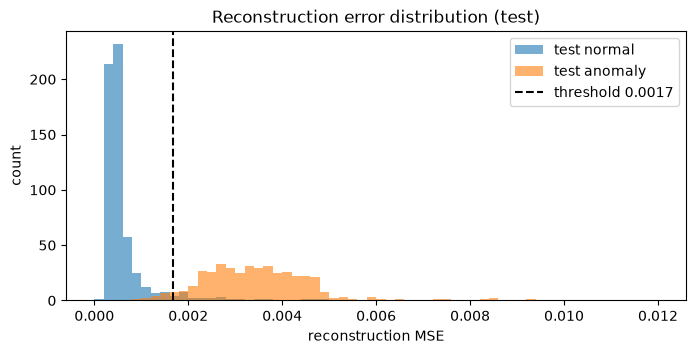

그래프 오른쪽 끝(0.012)보다 큰 이상 신호: 0 개


In [6]:
err_tr = recon_errors(ecg_model, normal_tr)           # 학습한 정상 신호의 복원 오차
err_te = recon_errors(ecg_model, X_te)
threshold = np.percentile(err_tr, 95)                 # 정상 신호의 95%가 이 값 아래
print(f"임계값(train 정상 오차의 95번째 백분위수): {threshold:.5f}")
print(f"평균 복원 오차  train 정상 {err_tr.mean():.5f} / test 정상 {err_te[y_te == 0].mean():.5f} / test 이상 {err_te[y_te == 1].mean():.5f}")

bins = np.linspace(0, 0.012, 61)
plt.figure(figsize=(8, 3.5))
plt.hist(err_te[y_te == 0], bins=bins, alpha=0.6, label="test normal")
plt.hist(err_te[y_te == 1], bins=bins, alpha=0.6, label="test anomaly")
plt.axvline(threshold, color="k", linestyle="--", label=f"threshold {threshold:.4f}")
plt.xlabel("reconstruction MSE"); plt.ylabel("count"); plt.title("Reconstruction error distribution (test)")
plt.legend(); plt.show()
print("그래프 오른쪽 끝(0.012)보다 큰 이상 신호:", (err_te[y_te == 1] > 0.012).sum(), "개")

**해석**
- 임계값은 **train 정상 신호 오차의 95번째 백분위수(0.00168)** 로 정했습니다. "정상 신호의 95%는 정상으로 통과시킨다"는 기준입니다. 임계값을 정할 때 test 라벨은 쓰지 않았습니다.
- 평균 복원 오차는 test 정상 0.00059, test 이상 0.00341로 **약 5.8배** 차이가 납니다. train 정상(0.00060)과 test 정상(0.00059)이 거의 같으므로, 모델이 학습한 신호만 외운 것이 아니라 정상 패턴 자체를 배웠습니다.
- 히스토그램에서 정상(파랑)은 0.001 아래에 몰려 있고, 이상(주황)은 0.002~0.005에 넓게 퍼져 있습니다. 두 분포가 겹치는 0.001~0.002 부근에서 오판이 생깁니다.

In [7]:
pred_te = (err_te > threshold).astype(int)            # 1 = 이상으로 판정
print(f"Precision {precision_score(y_te, pred_te):.4f}  Recall {recall_score(y_te, pred_te):.4f}  F1 {f1_score(y_te, pred_te):.4f}")
cm = confusion_matrix(y_te, pred_te)
print(pd.DataFrame(cm, index=["실제 정상", "실제 이상"], columns=["정상 판정", "이상 판정"]))

rows = []
for name, th in [("90번째 백분위수", np.percentile(err_tr, 90)),
                 ("95번째 백분위수 (선택)", threshold),
                 ("99번째 백분위수", np.percentile(err_tr, 99)),
                 ("평균 + 표준편차", err_tr.mean() + err_tr.std())]:
    p = (err_te > th).astype(int)
    rows.append({"임계값 기준": name, "임계값": round(th, 5),
                 "Precision": round(precision_score(y_te, p), 4),
                 "Recall": round(recall_score(y_te, p), 4),
                 "F1": round(f1_score(y_te, p), 4)})
pd.DataFrame(rows)

Precision 0.9343  Recall 0.9567  F1 0.9454
       정상 판정  이상 판정
실제 정상    556     28
실제 이상     18    398


,임계값 기준,임계값,Precision,Recall,F1
0,90번째 백분위수,0.00094,0.8737,0.9976,0.9315
1,95번째 백분위수 (선택),0.00168,0.9343,0.9567,0.9454
2,99번째 백분위수,0.00338,0.9758,0.4856,0.6485
3,평균 + 표준편차,0.00117,0.9057,0.9928,0.9472


**해석**
- 선택한 임계값(95번째 백분위수)에서 **Precision 0.934, Recall 0.957, F1 0.945** 입니다.
  - 이상 416개 중 **398개를 찾았고 18개를 놓쳤습니다**(Recall).
  - 이상으로 판정한 426개 중 28개는 실제로는 정상이었습니다(Precision). 정상 584개 중 약 4.8%로, 95번째 백분위수로 정한 의도(5%)와 거의 같습니다.
- 임계값을 바꾸면 Precision과 Recall이 서로 반대로 움직입니다.
  - 낮추면(90번째) 이상을 거의 다 찾지만(Recall 0.998) 정상을 이상으로 잘못 판정하는 경우가 늘어납니다(Precision 0.874).
  - 높이면(99번째) 판정은 정확하지만(Precision 0.976) 이상의 절반을 놓칩니다(Recall 0.486).
- 평균 + 표준편차 기준은 F1 0.947로 비슷하지만 Recall 쪽에 치우쳐 있습니다. 심박 이상 탐지처럼 **놓치는 비용이 큰 문제라면 임계값을 조금 낮추는 쪽**이 맞을 수 있습니다.
- 표의 다른 기준들은 비교용입니다. test 결과를 보고 임계값을 고르면 test에 맞춘 셈이 되므로, 선택은 train 기준(95번째 백분위수)으로 미리 정했습니다.

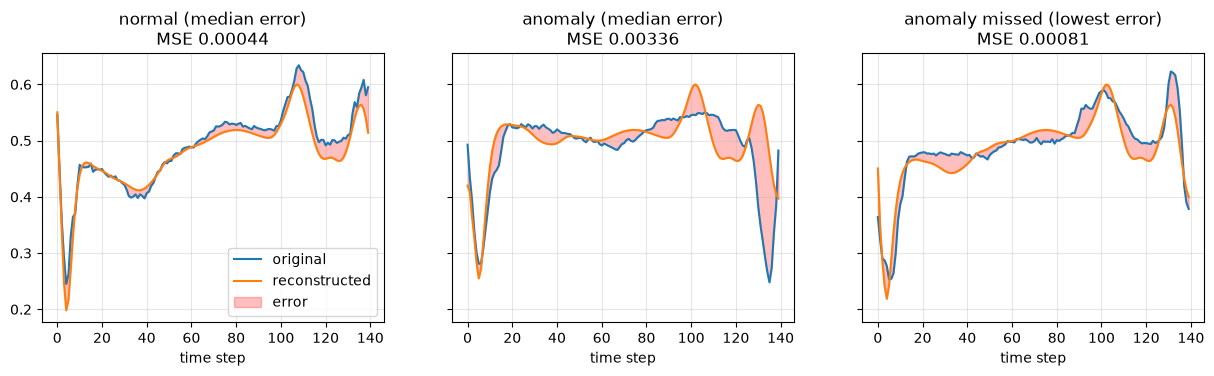

In [8]:
normal_ids = np.where(y_te == 0)[0]
anom_ids = np.where(y_te == 1)[0]
missed_ids = np.where((y_te == 1) & (pred_te == 0))[0]
pick = [("normal (median error)", normal_ids[np.argsort(err_te[normal_ids])[len(normal_ids) // 2]]),
        ("anomaly (median error)", anom_ids[np.argsort(err_te[anom_ids])[len(anom_ids) // 2]]),
        ("anomaly missed (lowest error)", missed_ids[np.argmin(err_te[missed_ids])])]

ecg_model.eval()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (title, k) in zip(axes, pick):
    with torch.no_grad():
        rec = ecg_model(torch.tensor(X_te[k:k + 1]).unsqueeze(-1).to(device))[0, :, 0].cpu().numpy()
    ax.plot(X_te[k], label="original")
    ax.plot(rec, label="reconstructed")
    ax.fill_between(range(140), X_te[k], rec, color="red", alpha=0.25, label="error")
    ax.set_title(f"{title}\nMSE {err_te[k]:.5f}"); ax.set_xlabel("time step"); ax.grid(alpha=0.3)
axes[0].legend()
plt.show()

**해석**
- **정상 신호(왼쪽):** 복원 곡선이 원본을 거의 그대로 따라갑니다. 앞쪽의 큰 골(0~10)과 뒤쪽의 봉우리(105~110)를 모두 맞췄습니다. 오차는 작은 떨림 정도입니다.
- **이상 신호(가운데):** 앞부분(0~90)은 잘 복원했지만 **뒷부분에서 크게 틀립니다.** 원본은 130 부근에서 아래로 크게 떨어지는데, 복원 곡선은 오히려 위로 올라가는 봉우리를 그립니다. 모델이 정상 신호에서만 본 **"뒤쪽에 봉우리가 있는 모양"으로 억지로 바꿔서** 복원한 것입니다. 오토인코더가 이상을 찾는 원리가 그대로 보입니다.
- **놓친 이상 신호(오른쪽):** 전체 모양이 정상과 매우 비슷해서 모델이 잘 복원했고, 오차(0.00081)가 임계값보다 작았습니다. 복원 오차만으로는 **정상과 비슷하게 생긴 이상은 찾기 어렵다**는 한계입니다.

### 심화 정리
| 항목 | 결과 |
| --- | --- |
| 모델 | LSTM 인코더-디코더 (hidden 64, 파라미터 34,369개), 정상 2,335개로 150 epoch 학습 |
| 평균 복원 오차 | test 정상 0.00059 / test 이상 0.00341 (약 5.8배) |
| 임계값 | train 정상 오차의 95번째 백분위수 = 0.00168 |
| test 성능 (이상 = 양성) | Precision 0.934, Recall 0.957, **F1 0.945** |

- 정상만 학습한 오토인코더는 이상 신호를 **정상처럼 바꿔서 복원**합니다. 그래서 복원 오차가 커지고, 이 차이로 이상을 찾을 수 있었습니다.
- 앞의 문서 복원 미션과 같은 오토인코더 원리를 씁니다. 다만 목적이 다릅니다. 문서 복원은 **복원 결과 자체**를 쓰고, 이상 탐지는 **복원이 얼마나 실패하는지**를 씁니다.
- 한계: 분할 한 번(test 1,000개)의 결과입니다. 정상과 모양이 비슷한 이상은 놓칩니다(18개).